# CPI LassoCV Forecast — Inflation-Only Predictor Set

**Correcting a mistake in `Inflation Pradeep.ipynb`:** that notebook trained its CPI LassoCV model on
*all 69 features from both the inflation panel and the growth panel* (ISM, S&P 500, jobless claims,
NFCI, permits, copper included alongside PPI, oil, rent, AHE, GSCPI). The L1 penalty then zeroed out
every traditional inflation variable and kept only S&P 500 and jobless claims — a model that
"forecasts CPI" using none of the actual inflation data available to it.

This notebook redoes the LassoCV inflation forecast using **only genuine inflation-side predictors** —
the same 7-variable panel already validated in `BVAR_Inflation_Forecast.ipynb`: **CPI** (target), PPI,
crude oil, the two Treasury breakeven rates, average hourly earnings, and the Global Supply Chain
Pressure Index. Zillow Rent and NY Fed Inflation Expectations are dropped for the same reason established
there — their short histories (2015– and 2013–) force `dropna()` to shrink the usable sample to
~117 months once HAR lag features are built; dropping them keeps a 246-month sample (2006–2026) instead.

**Method:** same overall design as the Pradeep notebook (HAR-style 1/3/12-month-lag features, COVID-era
sample down-weighting, rolling-window LassoCV backtest across 1–12-month horizons, HAR-X and naive
benchmarks, final multi-horizon refit and forecast) — just with the corrected, inflation-only feature set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display, Markdown

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (11, 4)

# Theme colors
navy_blue = '#13294B'
illini_orange = '#E84A27'
slate_grey = '#686F73'

COMBINED_FILE = 'Inflation_monthly_combined.xlsx'
OUTPUT_FILE = 'CPI_LassoCV_Forecast.xlsx'

FORECAST_HORIZONS = list(range(1, 13))
TEST_WINDOW_SIZE = 12
COVID_START, COVID_END = '2020-01-01', '2020-12-31'
RANDOM_STATE = 42

## 1. Load the inflation-only panel and build stationary transforms

In [2]:
panel = pd.read_excel(COMBINED_FILE, sheet_name='Raw_Monthly', index_col=0, parse_dates=True)

USE_COLS = ['CPI', 'PPI', 'OIL_AVG', 'T10YIE_EOM', 'T5YIE_EOM', 'AHE', 'GSCPI']
raw = panel[USE_COLS].dropna()

LOG_COLS = ['CPI', 'PPI', 'OIL_AVG', 'AHE']       # strictly positive, trending -> month-over-month log return
LEVEL_COLS = ['T10YIE_EOM', 'T5YIE_EOM', 'GSCPI']  # bounded rate/index series -> kept in levels

transformed = pd.DataFrame(index=raw.index)
for col in LOG_COLS:
    transformed[col] = np.log(raw[col]).diff()
for col in LEVEL_COLS:
    transformed[col] = raw[col]

transformed = transformed.dropna(how='all')

# Pre-shock anchoring: demean using the pre-COVID window, same convention as the Pradeep notebook
pre_shock_window = transformed.loc[:'2020-01-31']
pre_shock_mean = pre_shock_window.mean()
demeaned = transformed - pre_shock_mean

print(f"Sample: {demeaned.index.min().date()} to {demeaned.index.max().date()}  ({len(demeaned)} months)")
print("Dropped RENT and NYFED_EXP (short-history variables) to keep this longer, better-supported sample.")
demeaned.tail()

Sample: 2006-03-31 to 2026-08-31  (246 months)
Dropped RENT and NYFED_EXP (short-history variables) to keep this longer, better-supported sample.


,CPI,PPI,OIL_AVG,AHE,T10YIE_EOM,T5YIE_EOM,GSCPI
2026-04-30,0.004811,0.018147,0.099759,-0.000502,0.454072,0.926078,2.02515
2026-05-31,0.003149,0.029101,0.010960,0.000029,0.374072,0.776078,2.00515
2026-06-30,-0.005803,-0.067018,-0.186726,0.000557,0.234072,0.516078,1.37515
2026-07-31,-0.000833,0.007249,-0.055260,-0.000512,0.274072,0.516078,1.11515
2026-08-31,0.002383,0.010378,0.048214,0.000546,0.304072,0.566078,1.23515


## 2. COVID-era sample weighting

Same variance down-weighting as the Pradeep notebook: COVID-window observations get an inflated
variance scale, so the regression's `sample_weight` shrinks their influence without deleting them.

In [3]:
scale_factors = pd.Series(1.0, index=demeaned.index)
covid_scales = {
    '2020-03-31': 5.0, '2020-04-30': 10.0, '2020-05-31': 8.0,
    '2020-06-30': 5.0, '2020-07-31': 3.5,  '2020-08-31': 2.0,
    '2020-09-30': 1.5, '2020-10-31': 1.2,  '2020-11-30': 1.1,
}
for dt_str, scale in covid_scales.items():
    dt = pd.to_datetime(dt_str)
    if dt in scale_factors.index:
        scale_factors.loc[dt] = scale

sample_weights = 1.0 / scale_factors

## 3. HAR-style feature construction

Each variable contributes a 1-month lag, a trailing 3-month average lag, and a trailing 12-month average
lag — 7 base variables × 3 lag windows = 21 candidate predictors (vs. 69 in the uncorrected notebook).

In [4]:
def create_har_features(df):
    har_df = pd.DataFrame(index=df.index)
    for col in df.columns:
        har_df[f'{col}_1M_lag'] = df[col].shift(1)
        har_df[f'{col}_3M_lag'] = df[col].rolling(3).mean().shift(1)
        har_df[f'{col}_12M_lag'] = df[col].rolling(12).mean().shift(1)
    return har_df

X_features = create_har_features(demeaned).dropna()
print(f"X_features: {X_features.shape[0]} months x {X_features.shape[1]} predictors, "
      f"{X_features.index.min().date()} to {X_features.index.max().date()}")

X_features: 233 months x 21 predictors, 2007-04-30 to 2026-08-31


## 4. Rolling-window backtest: LassoCV vs. HAR-X vs. naive

For each horizon h (1–12 months), refit LassoCV (with `TimeSeriesSplit` cross-validated regularization)
and a hand-picked HAR-X model (CPI, PPI, oil only — the genuine cost-push variables) at each of the last
12 monthly test dates, using only data available at that date (no leakage).

In [5]:
valid_dates_for_h12 = X_features.index[:-12]
test_idx = valid_dates_for_h12[-TEST_WINDOW_SIZE:]

tscv = TimeSeriesSplit(n_splits=3)
results_lasso, results_har, results_naive = [], [], []

for h in FORECAST_HORIZONS:
    y_cpi = demeaned['CPI'].rolling(12).sum().shift(-h) if h == 12 else demeaned['CPI'].rolling(h).sum().shift(-h)
    model_df = X_features.join(y_cpi.rename('Y_CPI'), how='inner')
    w_aligned = sample_weights.loc[model_df.index]
    X = model_df[X_features.columns]

    err_lasso, err_har, err_naive = [], [], []
    for t_date in test_idx:
        X_train = X.loc[:t_date].iloc[:-h]
        y_train = model_df['Y_CPI'].loc[:t_date].iloc[:-h]
        w_train = w_aligned.loc[:t_date].iloc[:-h]
        X_test = X.loc[[t_date]]
        y_test = model_df['Y_CPI'].loc[t_date]

        naive_pred = demeaned['CPI'].rolling(h).sum().loc[t_date] if h > 1 else demeaned.loc[t_date, 'CPI']
        err_naive.append((naive_pred - y_test) ** 2)

        lasso = LassoCV(cv=tscv, random_state=RANDOM_STATE, max_iter=10000)
        lasso.fit(X_train, y_train, sample_weight=w_train.values)
        err_lasso.append((lasso.predict(X_test)[0] - y_test) ** 2)

        har_cols = [c for c in X.columns if any(k in c for k in ['CPI', 'PPI', 'OIL_AVG'])]
        har_model = sm.WLS(y_train, sm.add_constant(X_train[har_cols]), weights=w_train.values).fit()
        pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
        err_har.append((pred_har - y_test) ** 2)

    results_lasso.append({'months_ahead': h, 'RMSE': np.sqrt(np.mean(err_lasso))})
    results_har.append({'months_ahead': h, 'RMSE': np.sqrt(np.mean(err_har))})
    results_naive.append({'months_ahead': h, 'RMSE': np.sqrt(np.mean(err_naive))})

df_lasso_rmse = pd.DataFrame(results_lasso).set_index('months_ahead').round(6)
df_har_rmse = pd.DataFrame(results_har).set_index('months_ahead').round(6)
df_naive_rmse = pd.DataFrame(results_naive).set_index('months_ahead').round(6)

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

...

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]
C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (cons

C:\Users\Devminda\AppData\Local\Temp\ipykernel_31764\442266939.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pred_har = har_model.predict(sm.add_constant(X_test[har_cols], has_constant='add'))[0]


## 5. Compare accuracy across horizons

In [6]:
comparison = pd.DataFrame({
    'LassoCV': df_lasso_rmse['RMSE'],
    'HAR-X': df_har_rmse['RMSE'],
    'Naive': df_naive_rmse['RMSE'],
})
comparison['LassoCV_vs_Naive_%'] = 100 * (1 - comparison['LassoCV'] / comparison['Naive'])
comparison['HAR-X_vs_Naive_%'] = 100 * (1 - comparison['HAR-X'] / comparison['Naive'])
comparison

,LassoCV,HAR-X,Naive,LassoCV_vs_Naive_%,HAR-X_vs_Naive_%
months_ahead,,,,,
1,0.001189,0.001617,0.001137,-4.573439,-42.216359
2,0.002106,0.002788,0.002473,14.840275,-12.737566
3,0.002863,0.003494,0.003929,27.131586,11.071519
4,0.003378,0.004001,0.004889,30.906116,18.163224
5,0.003567,0.003906,0.005068,29.617206,22.928177
6,0.003737,0.003902,0.004469,16.379503,12.687402
7,0.005104,0.005212,0.004226,-20.776148,-23.331756
8,0.007311,0.007352,0.004551,-60.646012,-61.546913
9,0.009743,0.009789,0.005323,-83.035882,-83.900056


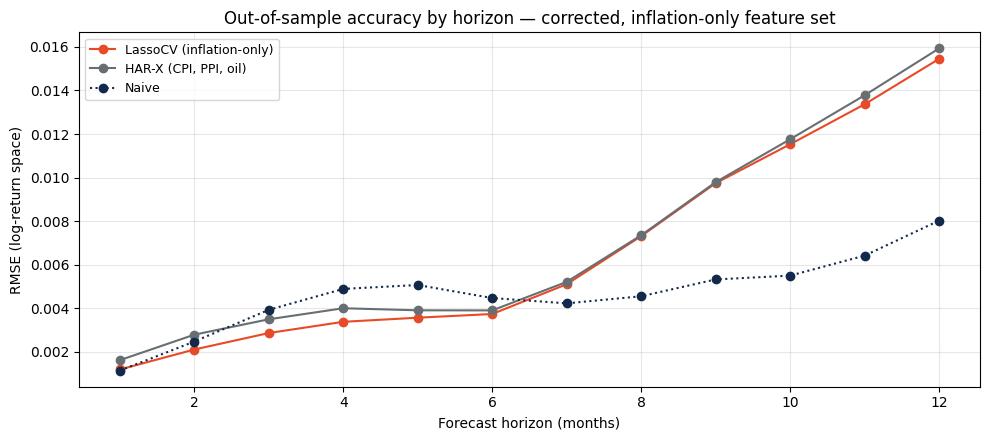

LassoCV beats naive by -30.1% (RMSE), averaged across all 12 horizons.
HAR-X beats naive by -40.5% (RMSE), averaged across all 12 horizons.


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(comparison.index, comparison['LassoCV'], marker='o', color=illini_orange, label='LassoCV (inflation-only)')
ax.plot(comparison.index, comparison['HAR-X'], marker='o', color=slate_grey, label='HAR-X (CPI, PPI, oil)')
ax.plot(comparison.index, comparison['Naive'], marker='o', color=navy_blue, linestyle=':', label='Naive')
ax.set_xlabel('Forecast horizon (months)')
ax.set_ylabel('RMSE (log-return space)')
ax.set_title('Out-of-sample accuracy by horizon — corrected, inflation-only feature set')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

avg_lasso_beat = comparison['LassoCV_vs_Naive_%'].mean()
avg_har_beat = comparison['HAR-X_vs_Naive_%'].mean()
print(f"LassoCV beats naive by {avg_lasso_beat:.1f}% (RMSE), averaged across all 12 horizons.")
print(f"HAR-X beats naive by {avg_har_beat:.1f}% (RMSE), averaged across all 12 horizons.")

## 6. Refit on the full sample and forecast 12 months ahead

Retrains LassoCV separately for each horizon on all available data, then predicts from the latest
observed feature row — same convention as the Pradeep notebook.

In [8]:
z_90, z_68 = stats.norm.ppf(0.95), 1.0

T0_date = demeaned.index[-1]
future_dates = pd.date_range(start=T0_date + pd.DateOffset(days=1), periods=12, freq='MS')
plot_dates = [T0_date] + list(future_dates)

latest_features = X_features.iloc[[-1]]
last_cpi_idx = raw['CPI'].iloc[-1]
pre_shock_cpi = pre_shock_mean['CPI']
hist_cpi = raw['CPI'].iloc[-36:]

point_fcs = []
final_lasso_h12 = None
for h in FORECAST_HORIZONS:
    y_cpi_h = demeaned['CPI'].rolling(12).sum().shift(-h) if h == 12 else demeaned['CPI'].rolling(h).sum().shift(-h)
    df_h = X_features.join(y_cpi_h.rename('Y_CPI'), how='inner').dropna()
    X_h, y_h, w_h = df_h[X_features.columns], df_h['Y_CPI'], sample_weights.loc[df_h.index]
    lasso_h = LassoCV(cv=tscv, random_state=RANDOM_STATE, max_iter=10000).fit(X_h, y_h, sample_weight=w_h.values)
    point_fcs.append(lasso_h.predict(latest_features)[0])
    if h == 12:
        final_lasso_h12 = lasso_h

# Fan-chart error bands: sorted out-of-sample RMSEs, so uncertainty strictly widens with horizon
se_sorted = np.sort(df_lasso_rmse['RMSE'].values)

medians = [0.0] + point_fcs
errors = [0.0] + list(se_sorted)
horizons = [1] + FORECAST_HORIZONS

df_plot = pd.DataFrame({'date': plot_dates, 'cum_return': medians, 'se': errors, 'h': horizons}).set_index('date')
df_plot['true_return'] = df_plot['cum_return'] + df_plot['h'] * pre_shock_cpi

df_plot['median'] = last_cpi_idx * np.exp(df_plot['true_return'])
df_plot['p05'] = last_cpi_idx * np.exp(df_plot['true_return'] - z_90 * df_plot['se'])
df_plot['p16'] = last_cpi_idx * np.exp(df_plot['true_return'] - z_68 * df_plot['se'])
df_plot['p84'] = last_cpi_idx * np.exp(df_plot['true_return'] + z_68 * df_plot['se'])
df_plot['p95'] = last_cpi_idx * np.exp(df_plot['true_return'] + z_90 * df_plot['se'])
df_plot['ann_inflation_pct'] = (np.exp(df_plot['true_return'] * (12 / df_plot['h'])) - 1) * 100

cpi_forecast_table = df_plot.iloc[1:][['p05', 'p16', 'median', 'p84', 'p95', 'ann_inflation_pct']].copy()
cpi_forecast_table.index = cpi_forecast_table.index.strftime('%Y-%m-%d')
cpi_forecast_table.reset_index(names=['date'], inplace=True)
cpi_forecast_table.style.hide(axis='index').format(precision=4)

date,p05,p16,median,p84,p95,ann_inflation_pct
2026-09-01,334.5024,334.7589,335.1572,335.5559,335.8133,3.7484
2026-10-01,334.9302,335.3854,336.0925,336.8010,337.2587,3.5743
2026-11-01,335.4235,336.0433,337.0068,337.9730,338.5976,3.4874
2026-12-01,336.0959,336.8288,337.9686,339.1122,339.8516,3.4853
2027-01-01,336.9439,337.7198,338.9266,340.1377,340.9210,3.4793
2027-02-01,337.6377,338.4524,339.7195,340.9914,341.8141,3.3731
2027-03-01,337.7313,338.8447,340.5786,342.3214,343.4499,3.3308
2027-04-01,337.3931,338.9875,341.4749,343.9806,345.6061,3.3149
2027-05-01,336.9289,339.0524,342.3720,345.7240,347.9030,3.3020
2027-06-01,336.7684,339.2817,343.2162,347.1964,349.7875,3.2717


### Fan chart — CPI index level

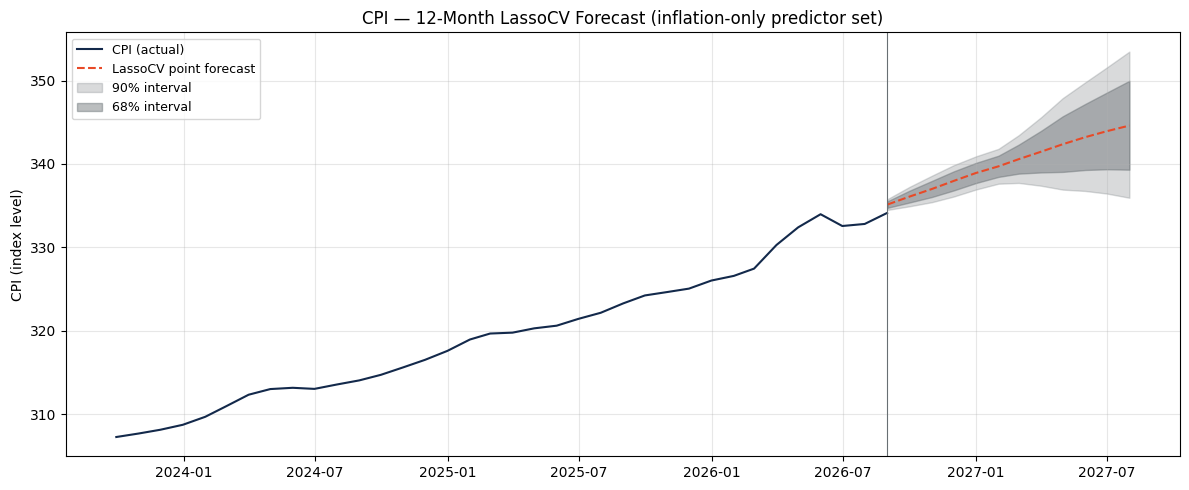

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_cpi.index, hist_cpi.values, color=navy_blue, label='CPI (actual)')
ax.plot(df_plot.index[1:], df_plot['median'].iloc[1:], color=illini_orange, linestyle='--', label='LassoCV point forecast')
ax.fill_between(df_plot.index[1:], df_plot['p05'].iloc[1:], df_plot['p95'].iloc[1:], color=slate_grey, alpha=0.25, label='90% interval')
ax.fill_between(df_plot.index[1:], df_plot['p16'].iloc[1:], df_plot['p84'].iloc[1:], color=slate_grey, alpha=0.45, label='68% interval')
ax.axvline(T0_date, color=slate_grey, linewidth=0.8)
ax.set_ylabel('CPI (index level)')
ax.set_title('CPI — 12-Month LassoCV Forecast (inflation-only predictor set)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fan chart — YoY inflation rate

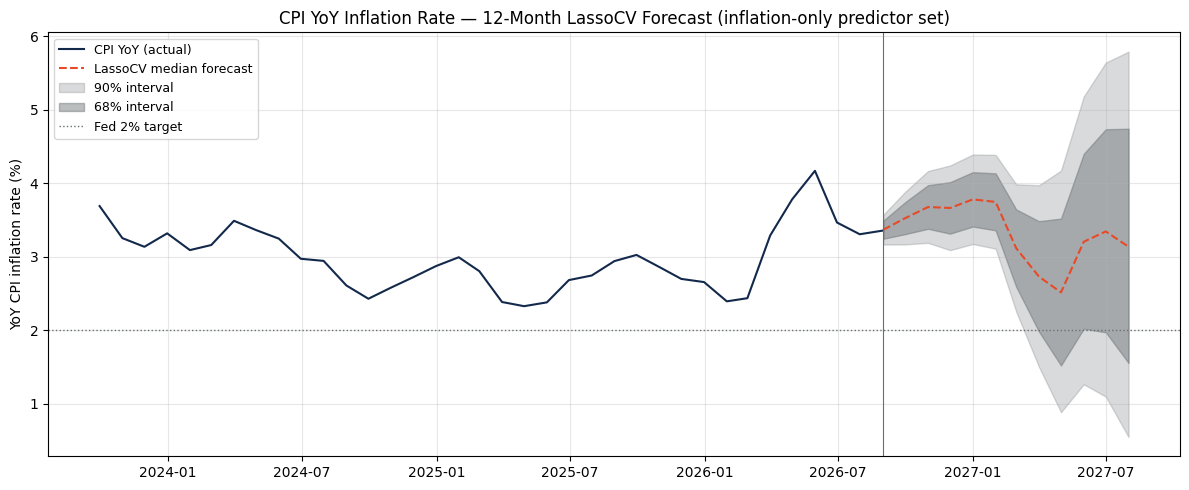

In [10]:
raw_cpi_by_period = raw['CPI'].copy()
raw_cpi_by_period.index = raw_cpi_by_period.index.to_period('M')

def cpi_level_to_yoy(level, date):
    base_period = pd.Timestamp(date).to_period('M') - 12
    base_val = raw_cpi_by_period.loc[base_period]
    return 100 * (level / base_val - 1)

forecast_yoy = pd.DataFrame(index=df_plot.index[1:])
for col in ['p05', 'p16', 'median', 'p84', 'p95']:
    forecast_yoy[col] = [cpi_level_to_yoy(v, d) for v, d in zip(df_plot[col].iloc[1:], df_plot.index[1:])]

cpi_yoy_hist_full = 100 * (raw['CPI'] / raw['CPI'].shift(12) - 1)
hist_tail_yoy = cpi_yoy_hist_full.iloc[-36:]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_tail_yoy.index, hist_tail_yoy.values, color=navy_blue, label='CPI YoY (actual)')
ax.plot(forecast_yoy.index, forecast_yoy['median'], color=illini_orange, linestyle='--', label='LassoCV median forecast')
ax.fill_between(forecast_yoy.index, forecast_yoy['p05'], forecast_yoy['p95'], color=slate_grey, alpha=0.25, label='90% interval')
ax.fill_between(forecast_yoy.index, forecast_yoy['p16'], forecast_yoy['p84'], color=slate_grey, alpha=0.45, label='68% interval')
ax.axhline(2.0, color=slate_grey, linestyle=':', linewidth=1, label='Fed 2% target')
ax.axvline(T0_date, color=slate_grey, linewidth=0.8)
ax.set_ylabel('YoY CPI inflation rate (%)')
ax.set_title('CPI YoY Inflation Rate — 12-Month LassoCV Forecast (inflation-only predictor set)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Predictor weight chart — which variables survive now

Same diagnostic as before, restricted to the corrected feature set. Since only inflation-side variables
were candidates, whatever survives is a genuine inflation driver — not a growth-side proxy standing in
for one.

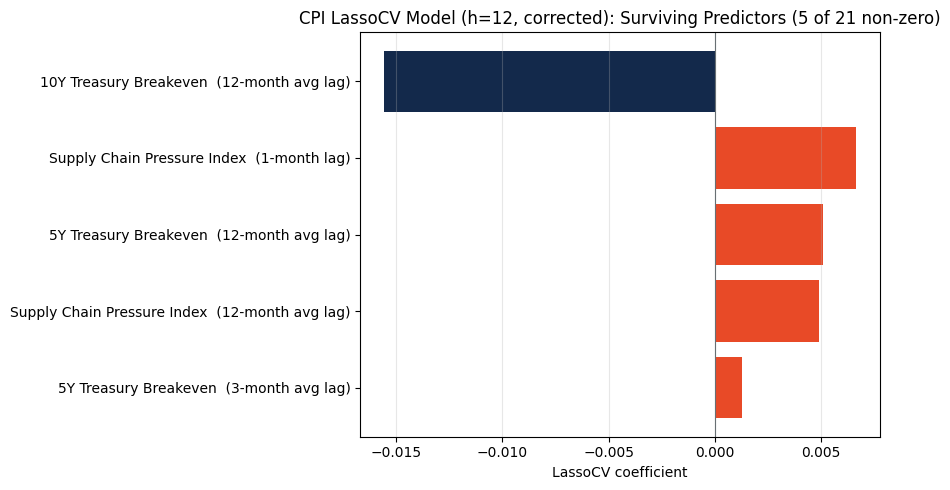

Selected alpha (h=12): 0.000148


In [11]:
VAR_LABELS = {
    'CPI': 'CPI (own history)', 'PPI': 'PPI (Unprocessed)', 'OIL_AVG': 'Crude Oil (WTI)',
    'T10YIE_EOM': '10Y Treasury Breakeven', 'T5YIE_EOM': '5Y Treasury Breakeven',
    'AHE': 'Average Hourly Earnings', 'GSCPI': 'Supply Chain Pressure Index',
}
LAG_SUFFIX_LABELS = {'_1M_lag': '1-month lag', '_3M_lag': '3-month avg lag', '_12M_lag': '12-month avg lag'}

def pretty_label(feat):
    for suffix, nice in LAG_SUFFIX_LABELS.items():
        if feat.endswith(suffix):
            base = feat[: -len(suffix)]
            return f"{VAR_LABELS.get(base, base)}  ({nice})"
    return feat

cpi_lasso_coefs = pd.Series(final_lasso_h12.coef_, index=X_features.columns)
nonzero = cpi_lasso_coefs[cpi_lasso_coefs != 0]
nonzero = nonzero.reindex(nonzero.abs().sort_values(ascending=True).index)
nonzero.index = [pretty_label(f) for f in nonzero.index]

fig, ax = plt.subplots(figsize=(9, 5))
colors = [illini_orange if v >= 0 else navy_blue for v in nonzero.values]
ax.barh(nonzero.index, nonzero.values, color=colors)
ax.axvline(0, color=slate_grey, linewidth=0.8)
ax.set_xlabel('LassoCV coefficient')
ax.set_title(f'CPI LassoCV Model (h=12, corrected): Surviving Predictors ({len(nonzero)} of {len(cpi_lasso_coefs)} non-zero)')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()
print(f"Selected alpha (h=12): {final_lasso_h12.alpha_:.6f}")

## 8. Export results

In [12]:
config_df = pd.DataFrame([
    {'parameter': 'variables', 'value': ', '.join(USE_COLS)},
    {'parameter': 'correction', 'value': 'Inflation-only predictor set (no growth-side variables); dropped RENT/NYFED_EXP for sample length, matching BVAR_Inflation_Forecast.ipynb'},
    {'parameter': 'sample', 'value': f'{demeaned.index.min().date()} to {demeaned.index.max().date()} ({len(demeaned)} months)'},
    {'parameter': 'har_features', 'value': f'{X_features.shape[1]} (7 vars x 1M/3M/12M lags)'},
    {'parameter': 'test_window_months', 'value': TEST_WINDOW_SIZE},
    {'parameter': 'forecast_horizon_months', 'value': 12},
    {'parameter': 'lasso_avg_pct_beat_naive', 'value': float(avg_lasso_beat)},
    {'parameter': 'har_avg_pct_beat_naive', 'value': float(avg_har_beat)},
    {'parameter': 'final_alpha_h12', 'value': float(final_lasso_h12.alpha_)},
])

with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    cpi_forecast_table.to_excel(writer, sheet_name='CPI_Forecast', index=False)
    comparison.to_excel(writer, sheet_name='Test_Evaluation')
    config_df.to_excel(writer, sheet_name='Model_Config', index=False)

print(f"Wrote {OUTPUT_FILE}")

Wrote CPI_LassoCV_Forecast.xlsx
